In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    "/Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance"
)

RESULTS_ROOT = (
    PROJECT_ROOT / "n_cmapss" / "outputs" / "tcn"
    / "window_256_stride_256"
)

if not RESULTS_ROOT.is_dir():
    raise FileNotFoundError(f"Sonuç klasörü bulunamadı: {RESULTS_ROOT}")

# Önceki çalışmalarda kullanılan LR=0.001 klasörleri.
# Hangisinin analiz edileceğini çıktıyı inceleyerek belirleyeceğiz.
candidate_dirs = [
    RESULTS_ROOT / "seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001",
    RESULTS_ROOT / "lr_0p001",
]

print("Stride=256 sonuç konumu:", RESULTS_ROOT)

for folder in candidate_dirs:
    print(f"\nDeney klasörü: {folder.name}")

    if not folder.is_dir():
        print("  Klasör mevcut değil.")
        continue

    prediction_files = sorted(folder.glob("fold_*/predictions.csv"))
    print(f"  Bulunan predictions.csv sayısı: {len(prediction_files)}")

    for file in prediction_files:
        print(f"  {file.relative_to(RESULTS_ROOT)}")

Stride=256 sonuç konumu: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/outputs/tcn/window_256_stride_256

Deney klasörü: seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001
  Bulunan predictions.csv sayısı: 6
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_1_20261122_231804_894998/predictions.csv
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_2_20261122_232355_770432/predictions.csv
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_3_20261122_232859_995265/predictions.csv
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_4_20261122_233615_819601/predictions.csv
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_5_20261122_234137_131759/predictions.csv
  seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001/fold_6_20261122_235023_275079/predictions.csv

Deney klasörü: lr_0p001
  Klasör mevcut değil.


# TCN — RUL Aralıklarına Göre Validation Hata Analizi

## Deney ve kapsam

- **Veri seti:** N-CMAPSS DS02-006
- **Pencere uzunluğu:** 256
- **Stride:** 256
- **Learning rate:** 0.001
- **Deney klasörü:** `seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001`
- **Değerlendirme:** 6 LOEO fold’una ait mevcut validation tahminleri

Her motor, kendisinin eğitim dışında bırakıldığı fold’un tahminleriyle
değerlendirilecektir. Eğitim ve resmî test tahminleri analize dahil edilmeyecektir.
Dosyaların fold ve motor eşleşmeleri sonraki adımlarda doğrulanacaktır.

## RUL aralıkları ve metrikler

Pencereler **gerçek RUL değerine** göre gruplandırılacaktır:

| Gerçek RUL (uçuş döngüsü) | Aralık |
|---|---|
| 0–20 | 0 ve 20 dahil |
| 21–40 | 21 ve 40 dahil |
| 41–60 | 41 ve 60 dahil |
| 61 ve üzeri | 61 dahil |

Her aralıkta pencere sayısı, MAE, RMSE ve Bias hesaplanacaktır.

**Hata = Tahmin edilen RUL − Gerçek RUL**

- **MAE:** Mutlak hataların ortalaması.
- **RMSE:** Kare hataların ortalamasının karekökü.
- **Bias:** İşaretli hataların ortalaması. Pozitif değer fazla, negatif değer
  eksik RUL tahminini gösterir.

Metrikler önce tüm validation pencereleri için, ardından motor bazında
incelenecektir. Birleştirilmiş hesaplamada her pencere eşit ağırlıktadır;
bu nedenle daha fazla penceresi olan motorlar sonuca daha fazla katkı yapar.

Bu çalışma mevcut validation sonuçlarının analizidir; bağımsız test
performansı olarak yorumlanmayacaktır.

In [2]:
import json
from IPython.display import display

EXPERIMENT_DIR = (
    RESULTS_ROOT / "seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001"
)

SPLITS_PATH = (
    PROJECT_ROOT / "n_cmapss" / "processed"
    / "window_256_stride_256" / "split_folds.json"
)

with SPLITS_PATH.open(encoding="utf-8") as file:
    split_config = json.load(file)

folds = sorted(split_config["folds"], key=lambda item: item["fold"])

assert [item["fold"] for item in folds] == list(range(1, 7)), (
    "1–6 arasındaki altı fold bekleniyor."
)

selected_files = {}
file_summary = []
seen_units = set()

for split in folds:
    fold = split["fold"]
    train_units = set(split["train_units"])
    validation_units = set(split["validation_units"])

    assert len(validation_units) == 1
    assert train_units.isdisjoint(validation_units)
    assert validation_units.isdisjoint(split_config["official_test_units"])

    unit = next(iter(validation_units))
    assert unit not in seen_units, "Motor birden fazla validation fold'unda."
    seen_units.add(unit)

    files = sorted(EXPERIMENT_DIR.glob(f"fold_{fold}_*/predictions.csv"))

    if len(files) != 1:
        raise ValueError(
            f"Fold {fold}: tam bir predictions.csv bekleniyor, "
            f"{len(files)} bulundu. Otomatik seçim yapılmadı."
        )

    path = files[0]
    predictions = pd.read_csv(path)

    required_columns = {
        "window_id", "unit", "cycle", "actual_rul", "predicted_rul"
    }
    assert required_columns.issubset(predictions.columns), (
        f"Fold {fold}: gerekli sütunlar eksik."
    )
    assert not predictions.empty, f"Fold {fold}: dosya boş."
    assert predictions["unit"].eq(unit).all(), (
        f"Fold {fold}: tahmin dosyasındaki motor validation motoruyla uyuşmuyor."
    )

    selected_files[fold] = path

    file_summary.append({
        "Fold": fold,
        "Validation motoru": unit,
        "Pencere sayısı": len(predictions),
        "Koşu klasörü": path.parent.name,
    })

file_summary = pd.DataFrame(file_summary)

display(file_summary)
print("Toplam validation penceresi:", file_summary["Pencere sayısı"].sum())
print("Kontrol başarılı: Her fold yalnızca kendi validation motorunu içeriyor.")

,Fold,Validation motoru,Pencere sayısı,Koşu klasörü
0,1,2,3294,fold_1_20261122_231804_894998
1,2,5,3990,fold_2_20261122_232355_770432
2,3,10,3685,fold_3_20261122_232859_995265
3,4,16,2955,fold_4_20261122_233615_819601
4,5,18,3446,fold_5_20261122_234137_131759
5,6,20,2969,fold_6_20261122_235023_275079


Toplam validation penceresi: 20339
Kontrol başarılı: Her fold yalnızca kendi validation motorunu içeriyor.


## Pencere Kimlikleri ve RUL Etiketlerinin Doğrulanması

Altı fold’da toplam **20.339 validation penceresi** bulundu.
Her tahmin dosyası yalnızca ilgili fold’un validation motorunu içeriyor.

Bir sonraki adımda tahminler, stride=256 için oluşturulan
`processed/window_256_stride_256/window_metadata.csv` ile karşılaştırılacaktır.

Kontroller:

- Pencere kimlikleri eksiksiz ve benzersiz olmalı.
- Her pencerenin motor ve uçuş bilgisi metadata ile eşleşmeli.
- `actual_rul`, metadata içindeki `rul` etiketiyle aynı olmalı.
- Gerçek ve tahmin edilen RUL değerleri sonlu olmalı.
- Gerçek RUL değerleri negatif olmamalı ve tam sayı olmalı.

Kontroller başarısız olursa kayıtlar silinmeden veya değiştirilmeden
analiz durdurulacaktır. Negatif tahminler varsa korunacaktır; bunlar
model hatasının bir parçasıdır.

In [3]:
METADATA_PATH = (
    PROJECT_ROOT / "n_cmapss" / "processed"
    / "window_256_stride_256" / "window_metadata.csv"
)

metadata = pd.read_csv(METADATA_PATH)

metadata_columns = ["window_id", "unit", "cycle", "rul"]
assert set(metadata_columns).issubset(metadata.columns)
assert metadata["window_id"].is_unique, "Metadata pencere kimlikleri tekrarlı."
assert np.isfinite(metadata[metadata_columns].to_numpy(dtype=float)).all()

validated_parts = []

for split in folds:
    fold = split["fold"]
    unit = split["validation_units"][0]

    predictions = pd.read_csv(selected_files[fold])
    expected = metadata.loc[
        metadata["unit"].eq(unit), metadata_columns
    ].copy()

    numeric_columns = [
        "window_id", "unit", "cycle", "actual_rul", "predicted_rul"
    ]
    assert np.isfinite(
        predictions[numeric_columns].to_numpy(dtype=float)
    ).all(), f"Fold {fold}: eksik veya sonsuz değer var."

    assert predictions["window_id"].is_unique, (
        f"Fold {fold}: tekrarlanan pencere kimliği var."
    )
    assert predictions["actual_rul"].ge(0).all(), (
        f"Fold {fold}: negatif gerçek RUL var."
    )
    assert predictions["actual_rul"].mod(1).eq(0).all(), (
        f"Fold {fold}: gerçek RUL tam sayı değil."
    )

    checked = predictions.merge(
        expected,
        on="window_id",
        how="outer",
        suffixes=("_prediction", "_metadata"),
        validate="one_to_one",
        indicator=True,
    )

    assert checked["_merge"].eq("both").all(), (
        f"Fold {fold}: eksik veya beklenmeyen pencereler var."
    )
    assert checked["unit_prediction"].eq(checked["unit_metadata"]).all(), (
        f"Fold {fold}: motor bilgileri uyuşmuyor."
    )
    assert checked["cycle_prediction"].eq(checked["cycle_metadata"]).all(), (
        f"Fold {fold}: uçuş bilgileri uyuşmuyor."
    )
    assert checked["actual_rul"].eq(checked["rul"]).all(), (
        f"Fold {fold}: gerçek RUL etiketleri uyuşmuyor."
    )

    validated_parts.append(
        predictions[numeric_columns].assign(fold=fold)
    )

validation_predictions = pd.concat(validated_parts, ignore_index=True)

assert validation_predictions["window_id"].is_unique, (
    "Aynı pencere birden fazla fold’da yer alıyor."
)
assert set(validation_predictions["window_id"]) == set(metadata["window_id"]), (
    "Birleştirilmiş tahminler metadata kapsamıyla uyuşmuyor."
)

print("Doğrulanan toplam pencere:", len(validation_predictions))
print("Motor sayısı:", validation_predictions["unit"].nunique())
print(
    "Gerçek RUL aralığı:",
    validation_predictions["actual_rul"].min(),
    "–",
    validation_predictions["actual_rul"].max(),
)
print(
    "Negatif tahmin sayısı (korundu):",
    validation_predictions["predicted_rul"].lt(0).sum(),
)
print("Pencere kimlikleri, motor, uçuş ve RUL etiketleri doğrulandı.")

display(validation_predictions.head())

Doğrulanan toplam pencere: 20339
Motor sayısı: 6
Gerçek RUL aralığı: 0.0 – 88.0
Negatif tahmin sayısı (korundu): 0
Pencere kimlikleri, motor, uçuş ve RUL etiketleri doğrulandı.


,window_id,unit,cycle,actual_rul,predicted_rul,fold
0,0,2,1,74.0,58.339378,1
1,1,2,1,74.0,56.798862,1
2,2,2,1,74.0,57.320042,1
3,3,2,1,74.0,58.363407,1
4,4,2,1,74.0,59.329769,1


## Gerçek RUL Değerlerine Göre Gruplandırma

Validation pencereleri, tahmin edilen değere değil **gerçek RUL değerine**
göre dört gruba ayrılacaktır:

| Grup | Koşul |
|---|---|
| 0–20 | 0 ≤ gerçek RUL ≤ 20 |
| 21–40 | 20 < gerçek RUL ≤ 40 |
| 41–60 | 40 < gerçek RUL ≤ 60 |
| 61 ve üzeri | gerçek RUL > 60 |

Gerçek RUL değerlerinin tam sayı olduğu doğrulandığından bu koşullar
istenen aralıkları eksiksiz karşılar. Her pencere yalnızca bir grupta
yer alacaktır.

Gruplandırmadan sonra pencere sayılarının toplamının **20.339**
olduğu ve hiçbir pencerenin grup dışında kalmadığı kontrol edilecektir.

In [4]:
RUL_LABELS = ["0–20", "21–40", "41–60", "61 ve üzeri"]

validation_predictions["rul_group"] = pd.cut(
    validation_predictions["actual_rul"],
    bins=[0, 20, 40, 60, np.inf],
    labels=RUL_LABELS,
    right=True,
    include_lowest=True,
    ordered=True,
)

assert validation_predictions["rul_group"].notna().all(), (
    "Bazı pencereler RUL aralıklarının dışında kaldı."
)

rul_counts = (
    validation_predictions
    .groupby("rul_group", observed=False)
    .size()
    .rename("Pencere sayısı")
    .rename_axis("Gerçek RUL aralığı")
    .to_frame()
)

assert rul_counts["Pencere sayısı"].sum() == len(validation_predictions)

display(rul_counts)
print("Toplam pencere:", rul_counts["Pencere sayısı"].sum())
print("Her pencere bir RUL grubuna atandı.")

,Pencere sayısı
Gerçek RUL aralığı,
0–20,5625
21–40,5541
41–60,5439
61 ve üzeri,3734


Toplam pencere: 20339
Her pencere bir RUL grubuna atandı.


## RUL Aralıklarına Göre MAE, RMSE ve Bias

Her pencere için hata şu şekilde tanımlanır:

**Hata = Tahmin edilen RUL − Gerçek RUL**

Her RUL aralığında:

- **Pencere sayısı:** Değerlendirilen validation pencerelerinin sayısı.
- **MAE:** Mutlak hataların ortalaması.
- **RMSE:** Kare hataların ortalamasının karekökü; büyük hatalara daha duyarlıdır.
- **Bias:** İşaretli hataların ortalaması.

Pozitif Bias, kalan ömrün ortalamada fazla tahmin edildiğini;
negatif Bias, az tahmin edildiğini gösterir. Bias’ın sıfıra yakın olması
tek başına düşük hata anlamına gelmez; pozitif ve negatif hatalar
birbirini dengeleyebilir.

MAE, RMSE ve Bias’ın birimi **uçuş döngüsüdür**.
Bu tabloda her pencere eşit ağırlıktadır; motorlara eşit ağırlık verilmez.

In [5]:
validation_predictions["error"] = (
    validation_predictions["predicted_rul"]
    - validation_predictions["actual_rul"]
)
validation_predictions["absolute_error"] = (
    validation_predictions["error"].abs()
)
validation_predictions["squared_error"] = (
    validation_predictions["error"].pow(2)
)

rul_metrics = (
    validation_predictions
    .groupby("rul_group", observed=False)
    .agg(
        window_count=("error", "size"),
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        bias=("error", "mean"),
    )
)

rul_metrics["rmse"] = np.sqrt(rul_metrics["mse"])

rul_metrics = (
    rul_metrics[["window_count", "mae", "rmse", "bias"]]
    .rename(columns={
        "window_count": "Pencere sayısı",
        "mae": "MAE",
        "rmse": "RMSE",
        "bias": "Bias",
    })
    .rename_axis("Gerçek RUL aralığı")
)

assert rul_metrics["Pencere sayısı"].sum() == len(validation_predictions)

display(
    rul_metrics.style.format({
        "Pencere sayısı": "{:d}",
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "Bias": "{:+.4f}",
    })
)

,Pencere sayısı,MAE,RMSE,Bias
Gerçek RUL aralığı,,,,
0–20,5625,1.0696,1.3300,+0.0843
21–40,5541,2.3146,3.2786,+0.6015
41–60,5439,4.6533,5.8177,+2.1943
61 ve üzeri,3734,7.1103,8.8784,-6.1142


## RUL Aralıklarına Göre İlk Bulgular

- **0–20:** MAE 1,0696 ve RMSE 1,3300 ile en düşük mutlak hata
  bu aralıkta görülüyor. Bias +0,0843; ortalama işaretli hata sıfıra yakın.
- **21–40:** MAE 2,3146. Bias +0,6015 ile ortalamada hafif fazla
  RUL tahmini görülüyor.
- **41–60:** MAE 4,6533. Bias +2,1943 ile ortalamada fazla
  RUL tahmini görülüyor.
- **61 ve üzeri:** MAE 7,1103 ve RMSE 8,8784 ile en yüksek mutlak
  hata bu aralıkta. Bias −6,1142; kalan ömür ortalamada eksik tahmin ediliyor.

Bu validation sonuçlarında gerçek RUL aralığı yükseldikçe MAE ve RMSE
artmaktadır. Bias grup ortalamasıdır; gruptaki her pencerenin aynı yönde
hatalı olduğu anlamına gelmez.

Sonuçlar pencere ağırlıklıdır. Aralıkların motor dağılımları farklı
olabileceğinden, bu eğilimin bütün motorlarda geçerli olup olmadığı
motor bazında ayrıca incelenecektir.

Sonraki adımda gerçek ve tahmin edilen RUL değerleri, ideal tahmini
gösteren **y = x** doğrusu ile karşılaştırılacaktır.

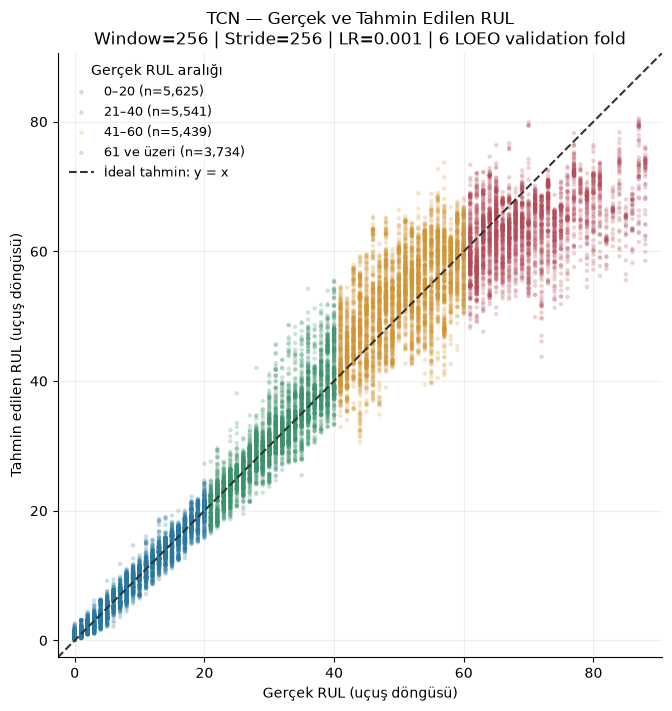

In [6]:
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)

colors = ["#2878A0", "#3B936C", "#D29532", "#B64B58"]

for label, color in zip(RUL_LABELS, colors):
    group = validation_predictions.loc[
        validation_predictions["rul_group"].eq(label)
    ]

    ax.scatter(
        group["actual_rul"],
        group["predicted_rul"],
        s=10,
        alpha=0.25,
        color=color,
        edgecolors="none",
        label=f"{label} (n={len(group):,})",
        rasterized=True,
    )

values = validation_predictions[["actual_rul", "predicted_rul"]]
lower = min(0, float(values.min().min()))
upper = float(values.max().max())
padding = max(1, (upper - lower) * 0.03)
limits = (lower - padding, upper + padding)

ax.plot(
    limits,
    limits,
    linestyle="--",
    color="#333333",
    linewidth=1.5,
    label="İdeal tahmin: y = x",
)

ax.set(
    xlim=limits,
    ylim=limits,
    xlabel="Gerçek RUL (uçuş döngüsü)",
    ylabel="Tahmin edilen RUL (uçuş döngüsü)",
    title=(
        "TCN — Gerçek ve Tahmin Edilen RUL\n"
        "Window=256 | Stride=256 | LR=0.001 | 6 LOEO validation fold"
    ),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Gerçek RUL aralığı", frameon=False, fontsize=9)

plt.show()

## Motor Bazında RUL Aralıklarına Göre Hata Analizi

Birleştirilmiş grafikte düşük gerçek RUL değerlerinde tahminler ideal
`y = x` doğrusuna daha yakın görünmektedir. Yüksek RUL değerlerinde
yayılım artmakta, özellikle 75–88 civarında eksik tahmin belirginleşmektedir.

Bu grafik altı farklı fold modelinin validation tahminlerini birlikte
gösterir. Görülen eğilimin bütün motorlarda aynı olduğu sonucuna
tek başına varılamaz.

Sonraki tabloda her motor ve gerçek RUL aralığı için şu değerler
hesaplanacaktır:

- Pencere sayısı
- MAE
- RMSE
- Bias

Her motor yalnızca kendisinin eğitim dışında bırakıldığı fold’un
tahminleriyle değerlendirilecektir.

Bir motorun belirli bir RUL aralığında penceresi yoksa pencere sayısı
0, hata metrikleri ise hesaplanamaz olarak gösterilecektir.
Bu durum sıfır hata anlamına gelmez.

Motorlar arasındaki farklar hem validation motorunun özelliklerinden
hem de fold’ların farklı eğitim motorlarıyla eğitilmesinden kaynaklanabilir.

In [7]:
motor_rul_metrics = (
    validation_predictions
    .groupby(["unit", "rul_group"], observed=False)
    .agg(
        window_count=("error", "size"),
        mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"),
        bias=("error", "mean"),
    )
)

motor_rul_metrics["rmse"] = np.sqrt(motor_rul_metrics["mse"])

motor_rul_metrics = (
    motor_rul_metrics[["window_count", "mae", "rmse", "bias"]]
    .rename(columns={
        "window_count": "Pencere sayısı",
        "mae": "MAE",
        "rmse": "RMSE",
        "bias": "Bias",
    })
    .rename_axis(index=["Motor", "Gerçek RUL aralığı"])
)

# Her motorun dört grubu ve bütün pencereleri tabloda bulunmalı.
assert len(motor_rul_metrics) == (
    validation_predictions["unit"].nunique() * len(RUL_LABELS)
)

expected_counts = (
    validation_predictions.groupby("unit").size().sort_index()
)
actual_counts = (
    motor_rul_metrics["Pencere sayısı"]
    .groupby(level="Motor").sum().sort_index()
)

np.testing.assert_array_equal(actual_counts.index, expected_counts.index)
np.testing.assert_array_equal(actual_counts.to_numpy(), expected_counts.to_numpy())

display(
    motor_rul_metrics.style.format(
        {
            "Pencere sayısı": "{:d}",
            "MAE": "{:.4f}",
            "RMSE": "{:.4f}",
            "Bias": "{:+.4f}",
        },
        na_rep="—",
    )
)

print("Toplam pencere:", motor_rul_metrics["Pencere sayısı"].sum())
print("Motor bazında pencere sayıları doğrulandı.")

Toplam pencere: 20339
Motor bazında pencere sayıları doğrulandı.


## Motor Bazındaki Bulgular

### Yüksek RUL: 61 ve üzeri

- Motor 2, 5, 10, 16 ve 18’de ortalama eksik RUL tahmini görülüyor.
- Motor 5, bu aralıkta en yüksek MAE (9,2352) ve RMSE (11,2542)
  değerlerine sahip. Bias −8,0782.
- Motor 20 diğer motorlardan ayrılıyor: Bias +1,3271 ile ortalamada
  fazla RUL tahmini görülüyor.

Dolayısıyla birleşik tablodaki negatif Bias, her motorun aynı yönde
hata yaptığı anlamına gelmiyor.

### Orta-yüksek RUL: 41–60

Motor 20’nin en yüksek hatası bu aralıkta:
MAE 7,0681, RMSE 8,4242 ve Bias +5,3587.

Motor 2’de de fazla tahmin belirgin: Bias +4,2342.
Motor 16 ise Bias −0,7024 ile bu aralıkta ortalamada eksik tahmin ediyor.

### Düşük RUL: 0–20

Bu aralık, altı motorun her birinde en düşük MAE ve RMSE’ye sahip.
Ancak hata yönü aynı değil; Motor 5 ve 18’de Bias negatif,
diğer dört motorda pozitif.

### Karşılaştırmanın sınırları

61 ve üzerindeki pencere sayısı motorlar arasında 106 ile 1.306 arasında
değişiyor. Motor 5, bu grubun toplam 3.734 penceresinin yaklaşık %35’ini
oluşturuyor ve birleşik metriğe daha fazla ağırlık veriyor.

Aynı RUL aralığındaki gerçek RUL dağılımları da motorlar arasında farklı
olabilir. Ayrıca aynı uçuşun pencereleri bağımsız gözlemler değildir;
pencere sayısı bağımsız uçuş sayısı olarak yorumlanmamalıdır.

Sonraki adımda gerçek ve tahmin edilen RUL ilişkisi, her motor için ayrı
bir panelde ve ortak eksen ölçekleriyle incelenecektir.

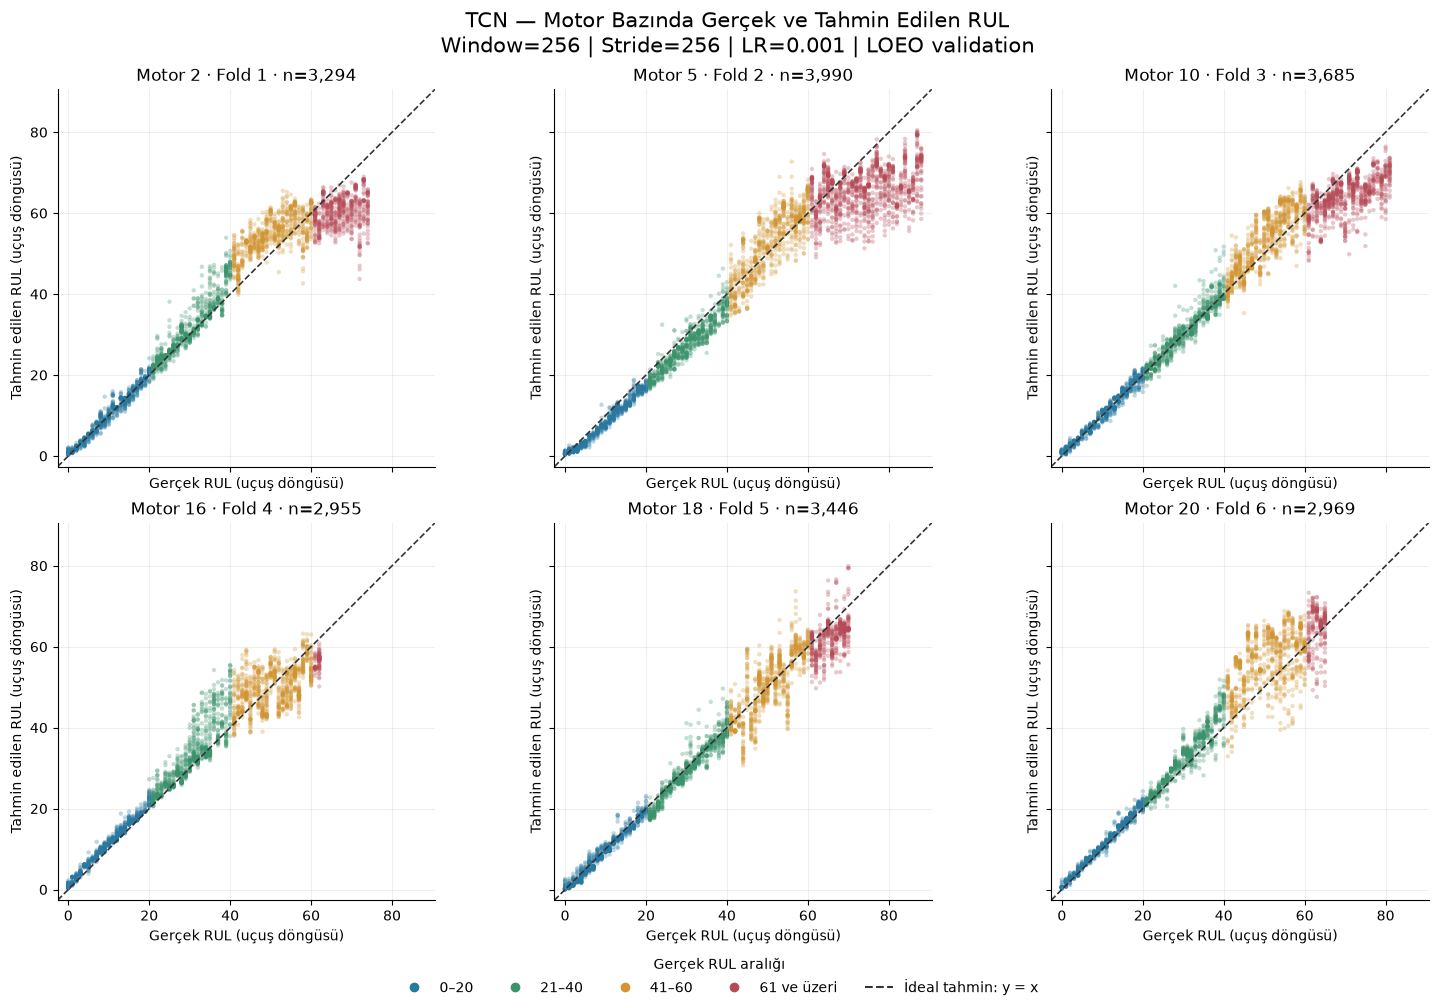

In [8]:
from matplotlib.lines import Line2D

units = sorted(validation_predictions["unit"].unique())
colors = dict(zip(
    RUL_LABELS,
    ["#2878A0", "#3B936C", "#D29532", "#B64B58"],
))

values = validation_predictions[["actual_rul", "predicted_rul"]]
lower = min(0, float(values.min().min()))
upper = float(values.max().max())
padding = max(1, (upper - lower) * 0.03)
limits = (lower - padding, upper + padding)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, unit in zip(axes.flat, units, strict=True):
    motor_data = validation_predictions.loc[
        validation_predictions["unit"].eq(unit)
    ]
    fold = int(motor_data["fold"].iloc[0])

    for label in RUL_LABELS:
        group = motor_data.loc[motor_data["rul_group"].eq(label)]

        ax.scatter(
            group["actual_rul"],
            group["predicted_rul"],
            s=10,
            alpha=0.3,
            color=colors[label],
            edgecolors="none",
            rasterized=True,
        )

    ax.plot(limits, limits, "--", color="#333333", linewidth=1.2)
    ax.set(
        xlim=limits,
        ylim=limits,
        title=f"Motor {unit} · Fold {fold} · n={len(motor_data):,}",
        xlabel="Gerçek RUL (uçuş döngüsü)",
        ylabel="Tahmin edilen RUL (uçuş döngüsü)",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

legend_handles = [
    Line2D(
        [], [], marker="o", linestyle="none",
        color=colors[label], label=label, markersize=6,
    )
    for label in RUL_LABELS
]
legend_handles.append(
    Line2D(
        [], [], color="#333333", linestyle="--",
        label="İdeal tahmin: y = x",
    )
)

fig.legend(
    handles=legend_handles,
    loc="outside lower center",
    ncol=5,
    frameon=False,
    title="Gerçek RUL aralığı",
)

fig.suptitle(
    "TCN — Motor Bazında Gerçek ve Tahmin Edilen RUL\n"
    "Window=256 | Stride=256 | LR=0.001 | LOEO validation",
    fontsize=15,
)

plt.show()